# 생활용품 SNS 리뷰 감성 분석
### 문장 단위로 "좋은 점"과 "아쉬운 점" 찾기 — Kiwi + KNU 한국어 감성사전

**환경:** Google Colab (인터넷 연결 필요)
**준비물:** `TS_5` 생활용품 리뷰 엑셀 파일 (SNS 리뷰 3,867건 — 위생용품, 주방용품, 세제/세정/탈취제)
**소요 시간:** 약 40분

## 오늘의 상황
> 생활용품 회사 마케팅 담당자입니다. 블로그 리뷰 3,867건을 다 읽을 수 없으니,
> **카테고리마다 소비자가 아쉬워하는 점**을 빠르게 찾고 싶습니다.

## 왜 "문장 단위"로 보나요?
SNS 리뷰는 대부분 칭찬이라 **리뷰 하나를 통째로 점수 매기면 96%가 긍정**으로 나옵니다(미리 확인한 값).
하지만 칭찬 리뷰 안에도 "다만 소음이 커서 시끄럽네요" 같은 **아쉬운 문장**이 숨어 있습니다.
그래서 리뷰를 **문장으로 나눠서** 문장마다 감성을 매깁니다.

## 실습 진행 과정
| 시간 | 단계 | 할 일 | 산출물 |
|---|---|---|---|
| 0. 준비 | 설치, 엑셀 읽기, 감성사전 내려받기 | 리뷰 수, 사전 크기 |
| 1. 텍스트 전처리 | 줄바꿈·가림 글자 정리 → 문장 나누기 → 인사 문장 빼기 → 단어 나누기 | 문장 목록 |
| 2. 정제 데이터셋 | 문장 표 정리, CSV 저장 | `review_sentences.csv` |
| 3. 텍스트 분석 | 문장 점수 → **감성사전 고치기** → 긍정/중립/부정 | 문장별 감성 |
| 4. 분석 결과 | 그래프 5종, 대표 불만 문장, **정답 세트로 정확도 확인** | 그래프, CSV 2개 |
| 정리 | 한계, 연습 문제 | — |

> **실행 방법:** 셀을 클릭하고 `Shift + Enter`. 반드시 **위에서부터 순서대로** 실행하세요.
> ✏️ 표시가 있는 곳은 **직접 바꿔 볼 수 있는 부분**입니다.

---
## 0. 준비
| 도구 | 하는 일 |
|---|---|
| `kiwipiepy` | 한국어 형태소 분석기 Kiwi (문장 나누기, 단어 나누기) |
| `wordcloud` | 워드클라우드 그리기 |
| `koreanize-matplotlib` | 그래프에 한글이 깨지지 않게 나눔고딕 글꼴 설정 |

In [1]:
# 도구 설치 (처음 한 번만)
# !        : 이 줄을 파이썬이 아닌 터미널 명령으로 실행
# pip install : 파이썬 도구(패키지)를 내려받아 설치하는 명령
# -q       : 설치 과정 메시지를 줄여서 출력
# kiwipiepy            : 한국어 형태소 분석기 Kiwi (문장 나누기, 단어 나누기)
# wordcloud            : 워드클라우드 그리기 도구
# koreanize-matplotlib : 그래프에 한글 글꼴(나눔고딕)을 설정해 주는 도구
!pip install -q kiwipiepy wordcloud koreanize-matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 MB 9.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 94.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 87.5 MB/s eta 0:00:00


> 🔧 설치 후 다음 셀에서 `PIL` 관련 `ImportError`가 나면: 메뉴 **런타임 → 세션 다시 시작** 후 설치 셀은 건너뛰고 다음 셀부터 실행하세요.

Colab 왼쪽 **📁 파일 창**에 `TS_5`로 시작하는 엑셀 파일을 끌어다 놓으세요.

In [2]:
# glob   : 파일 이름을 패턴으로 찾는 파이썬 기본 도구
# pandas : 표(DataFrame)를 다루는 도구, pd라는 짧은 이름으로 불러옴
import glob
import pandas as pd

# 'TS_5'로 시작하는 엑셀 파일 찾기
# 읽을 엑셀 파일 이름을 excel_path 변수에 저장 (괄호는 값에 영향을 주지 않음)
excel_path = ("TS_5.생활.xlsx")

# 엑셀 읽기
# pd.read_excel(경로): 엑셀 파일의 첫 번째 시트를 읽어 표(DataFrame)로 만듦
df = pd.read_excel(excel_path)

# 읽은 파일 이름과 리뷰 수(표의 행 수) 출력
print("파일:", excel_path)
print("리뷰 수:", len(df))

# value_counts(): '카테고리' 열의 값마다 리뷰가 몇 개인지 세어 많은 순으로 출력
print(df["카테고리"].value_counts())

# 리뷰 하나 보기 (✏️ 번호를 바꿔 보세요)
# df["상품평"][0]: '상품평' 열의 0번 행 리뷰, \n은 줄바꿈 문자
print("\n[리뷰 예시]\n" + df["상품평"][0])

파일: TS_5.생활.xlsx
리뷰 수: 3867
카테고리
위생용품         1767
주방용품         1154
세제/세정/탈취제     946
Name: count, dtype: int64

[리뷰 예시]
벌써 한 주가 다 지났네요. 나이가 든 걸까요, 시간이 너무 빨리 흘러 가네요. 제가 워킹맘이다 보니 빨래를 몰아서 할 때가 많아서 젖은 수건에서 가끔 퀘퀘한 냄새가 나서 고민이었는데 저의 고민은 해결해 준 고마운 녀석을 소개해 볼까 합니다. 

예전에 주문한 거 다 써서 또 주문했습니다. 다른 섬유유연제 특히 고농축 같은 건 물에 잘 퍼져 섞여야 한곳에 뭉치지 않는데 우리집 세탁기는 구형이라 그런게 잘 안되는건지 옷에 균일하게 퍼지지 않고 향이 뭉치는 경향이 있었는데 이건 그렇지 않아서 좋습니다.
인공적인 향기를 별로 좋아하지 않아서 거의 향이 느껴지지 않을 만큼 은은한것도 좋구요.   이 제품쓰면 정전기 잘 안나서 맘에 듭니다. 
수건만 따로 빨아 쓰는데 냄새 제거를 위해 서비스로 받은 섬유 향균제를 유연제와 함께 사용했는데 퀘퀘한 냄새가 사라지고 향긋한 향이 나서 이 제품도 따로 구매할 예정입니다.

여러분 뽀송뽀송하게 살자구요.~  오늘도 굿데이.


### KNU 한국어 감성사전
군산대학교에서 만든 공개 감성사전입니다. 한 줄에 `단어<탭>점수`가 있고, 점수는 **−2(매우 부정) ~ +2(매우 긍정)** 입니다.

In [3]:
# csv: 표 파일 읽기 옵션(따옴표 처리 방식)을 지정할 때 쓰는 파이썬 기본 도구
import csv

# 감성사전 읽기 (GitHub 주소에서 바로 읽음)
# url: KNU 한국어 감성사전 파일의 인터넷 주소
url = "https://raw.githubusercontent.com/park1200656/KnuSentiLex/master/SentiWord_Dict.txt"

# pd.read_csv(...)         : 주소의 파일을 읽어 표로 만듦
#   sep="\t"               : 칸 구분 기호를 탭 문자로 지정
#   header=None            : 첫 줄을 열 이름이 아니라 데이터로 읽음
#   names=["단어", "점수"]  : 두 열에 이름을 붙임
#   quoting=csv.QUOTE_NONE : 따옴표(")를 특수 기호가 아닌 일반 글자로 취급
# .dropna()                : 빈 값이 있는 행을 지움
lex = pd.read_csv(url, sep="\t", header=None, names=["단어", "점수"], quoting=csv.QUOTE_NONE).dropna()

# {단어: 점수} 사전으로 만들기 (고치기 전 원본)
#   lex["단어"].str.strip() : 단어 앞뒤의 공백 제거
#   lex["점수"].astype(int) : 점수를 정수로 변환
#   zip(A, B)              : 같은 위치의 단어와 점수를 (단어, 점수) 쌍으로 묶음
#   dict(...)              : 쌍들을 {단어: 점수} 사전(딕셔너리)으로 만듦
knu_raw = dict(zip(lex["단어"].str.strip(), lex["점수"].astype(int)))

# 사전에 들어 있는 단어 수 출력
print("감성사전 크기:", len(knu_raw))

감성사전 크기: 14851


---
## 1. 텍스트 데이터 전처리

### 💡 이 데이터의 특징
| 특징 | 예 | 처리 방법 |
|---|---|---|
| 문장 **중간에서 줄이 바뀜** | `베이킹` ↵ `소다로 씻어내고` | 줄바꿈을 띄어쓰기로 바꾼 뒤 문장 나누기 |
| 상품명 **가림 글자** | `OO 주방세제`, `뮤**`, `ㅇㅇㅇ 치약` | 지우기 |
| 블로그 **인사·소개 문장** | `안녕하세요`, `오늘도 클릭해 주셔서 감사합니다` | 빼기 (제품 평가가 아님) |
| 마침표 없는 문장 | `좋아요~~`, `별로네요ㅠㅠ` | Kiwi의 **문장 나누기** 기능 사용 |

In [4]:
# re   : 정규표현식(글자 패턴) 도구
# Kiwi : 한국어 형태소 분석기 클래스
import re
from kiwipiepy import Kiwi

# Kiwi 분석기 만들기 (처음 만들 때 사전을 불러오느라 몇 초 걸림)
kiwi = Kiwi()

# 줄바꿈 → 띄어쓰기, 가림 글자(OO, O냄새의 O, ㅇㅇ, **) 지우기, 여러 칸 띄어쓰기 → 한 칸
#   (?<![A-Za-z])O+(?![A-Za-z]) : 앞뒤에 다른 영어 글자가 없는 O (영어 단어 안의 O는 남김)
#   ㅇ{2,}                      : ㅇ이 2개 이상 이어진 부분 (ㅇㅇ, ㅇㅇㅇ)
#   \*{2,}                      : *이 2개 이상 이어진 부분 (**)
#   \s+                         : 공백 문자가 1개 이상 이어진 부분
# .str.replace(패턴, 바꿀 글자, regex=True): 모든 리뷰에서 패턴에 맞는 부분을 바꿈
# 결과를 새 열 '본문'에 저장
df["본문"] = (df["상품평"]
              .str.replace(r"\n", " ", regex=True)
              .str.replace(r"(?<![A-Za-z])O+(?![A-Za-z])|ㅇ{2,}|\*{2,}", "", regex=True)
              .str.replace(r"\s+", " ", regex=True))

# 리뷰마다 문장 나누기 → [리뷰 번호, 카테고리, 상품명, 문장] 목록
# 문장 한 줄씩 모을 빈 리스트
rows = []

# kiwi.split_into_sents(리뷰 목록): 리뷰마다 문장 목록을 차례로 돌려줌
# enumerate: (리뷰 번호 i, 그 리뷰의 문장 목록 sents)를 함께 꺼냄
for i, sents in enumerate(kiwi.split_into_sents(df["본문"])):
    # 문장 하나씩 꺼내 [리뷰 번호, 카테고리, 상품명, 문장 글자]를 rows에 추가
    for s in sents:
        rows.append([i, df["카테고리"][i], df["상품명"][i], s.text])

# rows를 네 열짜리 표로 변환
sent = pd.DataFrame(rows, columns=["리뷰ID", "카테고리", "상품명", "문장"])

# 나뉜 문장 수 출력, 표의 앞 5행 보기
print("나뉜 문장 수:", len(sent))
sent.head()

나뉜 문장 수: 39161


,리뷰ID,카테고리,상품명,문장
0,0,세제/세정/탈취제,OO 고농축 섬유유연제 뮤** 1.6L,벌써 한 주가 다 지났네요.
1,0,세제/세정/탈취제,OO 고농축 섬유유연제 뮤** 1.6L,"나이가 든 걸까요, 시간이 너무 빨리 흘러 가네요."
2,0,세제/세정/탈취제,OO 고농축 섬유유연제 뮤** 1.6L,제가 워킹맘이다 보니 빨래를 몰아서 할 때가 많아서 젖은 수건에서 가끔 퀘퀘한 냄새...
3,0,세제/세정/탈취제,OO 고농축 섬유유연제 뮤** 1.6L,예전에 주문한 거 다 써서 또 주문했습니다.
4,0,세제/세정/탈취제,OO 고농축 섬유유연제 뮤** 1.6L,다른 섬유유연제 특히 고농축 같은 건 물에 잘 퍼져 섞여야 한곳에 뭉치지 않는데 우...


### 인사·소개 문장과 짧은 문장 빼기
**✏️ [입력]** `GREETING`에 빼고 싶은 표현을 `|`(또는)로 더해 보세요.

In [5]:
# ===== ✏️ [입력] 뺄 인사·소개 표현 =====
# 인사·소개 문장에 자주 나오는 표현을 |(또는)로 이은 정규표현식
GREETING = "안녕|클릭|이웃|포스팅|댓글|구독|소개해|소개할|소개하려|오늘은|오늘도"
# =====================================

# 인사·소개 표현이 있는 문장 표시
# .str.contains(GREETING): 문장에 표현 중 하나라도 있으면 True, 없으면 False
is_greeting = sent["문장"].str.contains(GREETING)

# True의 개수(빠지는 문장 수)와, 빠지는 문장 앞 5개를 리스트로 출력
print("빠지는 인사·소개 문장:", is_greeting.sum())
print(sent[is_greeting]["문장"].head(5).tolist())

# 인사 문장이 아니고 10자 이상인 문장만 남기기
#   ~is_greeting                    : True/False 뒤집기 (인사 문장이 아니면 True)
#   sent["문장"].str.len() >= 10    : 글자 수가 10 이상이면 True
#   &                               : 두 조건이 모두 True인 행만 선택
#   .reset_index(drop=True)         : 행 번호를 0부터 다시 매김
sent = sent[~is_greeting & (sent["문장"].str.len() >= 10)].reset_index(drop=True)

# 남은 문장 수 출력
print("남은 문장 수:", len(sent))

빠지는 인사·소개 문장: 3688
['제가 워킹맘이다 보니 빨래를 몰아서 할 때가 많아서 젖은 수건에서 가끔 퀘퀘한 냄새가 나서 고민이었는데 저의 고민은 해결해 준 고마운 녀석을 소개해 볼까 합니다.', '오늘도 굿데이.', '매일매일 하는 힘든 세탁이지만 오늘 소개해드린 이 세제의 매력에 한번 빠져보는 것도 좋을듯합니다.', '은은한 향을 좋아하신다면 오늘은 아우라에서 나온 섬유유연제 한번 소개해 볼게요', '오늘은 성분이 좋아 피부약한 사람에게도 너무 좋은 섬유유연제를 소개해 드렸는데 도움이 되셨는지 모르겠네요']
남은 문장 수: 33385


### 단어 나누기
앞 실습과 같은 규칙입니다.
- 동사·형용사는 `좋다`처럼 `다`, 어근은 `은은하다`처럼 `하다`를 붙여 **감성사전 모양**에 맞춤
- 뜻을 뒤집는 `안`, `못`, 평가하는 `별로`는 꼭 남김
- 그래프용으로 **두 글자 이상 명사**만 따로 모음

In [6]:
# 형태소 분석 결과 → 감성사전 모양의 단어 목록
# tokens: 문장 하나의 형태소(토큰) 목록, 각 토큰 t는 t.form(글자), t.tag(품사 태그)를 가짐
def to_words(tokens):
    # 결과 단어를 모을 빈 리스트
    words = []
    for t in tokens:
        tag = t.tag.split("-")[0]           # 'VA-I' → 'VA' (뒤에 붙은 표시 떼기)
        # VV(동사), VA(형용사), 또는 '않'(않다의 어간)이면
        if tag in {"VV", "VA"} or t.form == "않":
            words.append(t.form + "다")      # 동사·형용사: '다' 붙이기
        # XR(어근, 예: 은은)이면
        elif tag == "XR":
            words.append(t.form + "하다")    # 어근: '하다' 붙이기
        # NNG(일반명사), NNP(고유명사), 또는 '안', '못', '별로'이면
        elif tag in {"NNG", "NNP"} or t.form in {"안", "못", "별로"}:
            words.append(t.form)            # 명사, 부정·평가 표현은 그대로
    # 그 외 품사(조사, 어미 등)는 버리고 모은 단어 목록을 돌려줌
    return words

# 모든 문장을 한 번에 분석 (30초 정도 걸림)
# kiwi.tokenize(문장 목록): 문장마다 형태소 목록을 돌려줌, list(...)로 전부 받아 저장
tokens = list(kiwi.tokenize(sent["문장"].tolist()))

# 감성 점수용 단어, 그래프용 명사(일반명사, 두 글자 이상)
# '단어' 열: 문장마다 to_words로 만든 단어 목록
sent["단어"] = [to_words(t) for t in tokens]
# '명사' 열: 문장마다 태그가 NNG이고 글자 수가 2 이상인 형태소의 글자만 모은 목록
sent["명사"] = [[x.form for x in t if x.tag == "NNG" and len(x.form) > 1] for t in tokens]

# 원문과 비교
# 3번 문장의 원문, 단어 목록, 명사 목록 출력
print(sent["문장"][3])
print(sent["단어"][3])
print(sent["명사"][3])

다른 섬유유연제 특히 고농축 같은 건 물에 잘 퍼져 섞여야 한곳에 뭉치지 않는데 우리집 세탁기는 구형이라 그런게 잘 안되는건지 옷에 균일하게 퍼지지 않고 향이 뭉치는 경향이 있었는데 이건 그렇지 않아서 좋습니다.
['섬유', '유연제', '농축', '같다', '물', '퍼지다', '섞이다', '곳', '뭉치다', '않다', '집', '세탁기', '구형', '그러다', '안', '되다', '옷', '균일', '퍼지다', '않다', '향', '뭉치다', '경향', '있다', '그렇다', '않다', '좋다']
['섬유', '유연제', '농축', '세탁기', '구형', '균일', '경향']


---
## 2. 정제 데이터셋
문장 번호를 붙이고 CSV로 저장합니다. 단어 목록은 띄어쓰기로 이어 붙여 저장합니다.

In [7]:
# 문장ID: S00000 형식 번호를 맨 앞 열에 넣기
# sent.insert(위치, 열 이름, 값 목록): 0번 위치(맨 앞)에 새 열 추가
# f"S{i:05d}": i를 다섯 자리로 맞추고 앞을 0으로 채운 글자 (예: S00012)
sent.insert(0, "문장ID", [f"S{i:05d}" for i in range(len(sent))])

# 단어 목록을 글자로 바꿔서 CSV 저장 (utf-8-sig: 엑셀 한글 깨짐 방지)
#   .str.join(" ")  : 목록 안의 단어들을 띄어쓰기로 이어 한 줄 글자로 만듦
#   .assign(...)    : '단어', '명사' 열을 글자로 바꾼 새 표를 만듦 (원래 sent는 그대로)
#   .to_csv(...)    : 그 표를 CSV 파일로 저장, index=False는 행 번호를 저장하지 않음
#   \              : 다음 줄로 코드를 이어 씀
sent.assign(단어=sent["단어"].str.join(" "), 명사=sent["명사"].str.join(" ")) \
    .to_csv("review_sentences.csv", index=False, encoding="utf-8-sig")

# 정제된 문장 수, 리뷰 한 개당 평균 문장 수(소수 첫째 자리), 카테고리별 문장 수 출력
print("정제된 문장 수:", len(sent))
print("리뷰 한 개당 문장 수:", round(len(sent) / len(df), 1))
print(sent["카테고리"].value_counts())

정제된 문장 수: 33385
리뷰 한 개당 문장 수: 8.6
카테고리
위생용품         15302
주방용품         10287
세제/세정/탈취제     7796
Name: count, dtype: int64


> ⚠️ 이 셀을 두 번 실행하면 `문장ID` 열이 이미 있어서 오류가 납니다. 그럴 때는 1단계부터 다시 실행하세요.

---
## 3. 텍스트 분석: 문장 감성 점수

### 💡 점수 매기는 규칙 (앞 실습과 같음)
1. 단어마다 감성사전 점수를 더합니다. (사전에 없으면 0점)
2. 바로 앞에 `안`·`못`, 바로 뒤에 `않다`·`없다`가 있으면 **부호를 뒤집습니다.** (`안 좋다` → −2)
3. 합계 **> 0 긍정, = 0 중립, < 0 부정**

In [8]:
# 부호를 뒤집는 말
# FLIP_BEFORE: 단어 앞에 와서 뒤 단어의 점수 부호를 뒤집는 말 (예: 안 좋다)
# FLIP_AFTER : 단어 뒤에 와서 앞 단어의 점수 부호를 뒤집는 말 (예: 좋지 않다, 불편 없다)
FLIP_BEFORE = {"안", "못"}
FLIP_AFTER = {"않다", "없다"}

# 단어 목록 하나의 감성 점수
# words: 문장 하나의 단어 목록, lexicon: {단어: 점수} 감성사전
def score(words, lexicon):
    # 점수 합계를 0에서 시작
    total = 0
    # enumerate: (위치 j, 단어 w)를 차례로 꺼냄
    for j, w in enumerate(words):
        if w in FLIP_BEFORE or w in FLIP_AFTER:   # 부정어 자체는 0점
            continue
        value = lexicon.get(w, 0)                 # 사전에 없으면 0점
        # 바로 앞 단어 (첫 단어면 빈 글자)
        before = words[j - 1] if j > 0 else ""
        # 바로 뒤 단어 (마지막 단어면 빈 글자)
        after = words[j + 1] if j + 1 < len(words) else ""
        if before in FLIP_BEFORE or after in FLIP_AFTER:
            value = -value                        # 앞뒤 부정어가 있으면 부호 뒤집기
        # 이 단어의 점수를 합계에 더함
        total += value
    # 문장의 점수 합계를 돌려줌
    return total

# 점수 → 긍정 / 중립 / 부정
# 0보다 크면 "긍정", 0보다 작으면 "부정", 0이면 "중립"을 돌려줌
def label(s):
    return "긍정" if s > 0 else ("부정" if s < 0 else "중립")

# 고치기 전 사전으로 모든 문장 점수 매기기
# '점수_전' 열: 문장마다 원본 사전(knu_raw)으로 계산한 점수
sent["점수_전"] = [score(w, knu_raw) for w in sent["단어"]]

# 점수를 감성으로 바꾸고(.apply(label)), 감성별 비율(normalize=True)을 소수 셋째 자리로 출력
print(sent["점수_전"].apply(label).value_counts(normalize=True).round(3))

점수_전
긍정    0.557
중립    0.350
부정    0.093
Name: proportion, dtype: float64


### 🔍 어떤 단어가 점수를 움직였을까?
점수에 가장 많이 반영된 단어를 보면 **생활용품 리뷰와 맞지 않는 단어**가 보입니다.

In [9]:
# Counter: 항목별 개수를 세어 주는 도구
from collections import Counter

# 사전 점수가 0이 아닌 단어 세기 (부호를 뒤집는 '않다', '없다'는 점수에 안 쓰므로 제외)
# 모든 문장의 단어를 하나씩 꺼내, 원본 사전 점수가 0이 아니고 FLIP_AFTER에 없는 단어만 셈
used = Counter(w for words in sent["단어"] for w in words
               if knu_raw.get(w, 0) != 0 and w not in FLIP_AFTER)

# (단어, 사전 점수, 등장 횟수) 상위 20개
# used.most_common(20): 많이 나온 순서로 (단어, 횟수) 20개
print([(w, knu_raw[w], n) for w, n in used.most_common(20)])

[('좋다', 2, 9326), ('만족', 2, 1448), ('저렴하다', 1, 1303), ('많다', 2, 1241), ('편하다', 2, 1058), ('크다', 1, 663), ('깨끗하다', 2, 660), ('부드럽다', 1, 565), ('비싸다', -2, 525), ('도움', 1, 503), ('예쁘다', 2, 436), ('적당하다', 1, 424), ('받다', 1, 415), ('괜찮다', 1, 395), ('좋아하다', 2, 382), ('깔끔하다', 2, 367), ('걱정', -2, 364), ('맛있다', 2, 342), ('개운하다', 2, 332), ('힘들다', -2, 314)]


### 감성사전 고치기
| 문제 | 예 | 해결 |
|---|---|---|
| 인사말 | `감사`(+2): "읽어주셔서 감사합니다" | 0점 |
| 뜻이 다른 단어 | `용기`(+1): 사전은 '용감함', 리뷰는 '그릇' | 0점 |
| 감정과 관계없는 단어 | `많다`(+2), `받다`, `크다` | 0점 |
| **제품이 없애는 대상** | `곰팡이`, `먼지`, `냄새`: "곰팡이가 싹 지워져요"는 칭찬 | 0점 |
| 사전에 없는 표현 | `은은하다`, `풍성하다`, `단점`, `날카롭다` | 직접 추가 |

**✏️ [입력]** 결과를 보고 단어를 더하거나 빼 보세요.

In [10]:
# ===== ✏️ [입력] 감성사전 고치기 =====
# 0점으로 바꿀 단어
ignore_words = ["감사", "용기", "많다", "받다", "크다", "고르다", "곰팡이", "먼지", "냄새", "때", "얼룩", "부담", "걱정"]

# 추가하거나 점수를 바꿀 단어 (−2 ~ +2)
# {단어: 점수} 형태의 사전
add_words = {"은은하다": 1, "풍성하다": 1, "별로": -2, "아쉽다": -1, "단점": -1, "흠": -1,
             "날카롭다": -1, "시끄럽다": -1, "찢어지다": -1, "거칠다": -1, "번거롭다": -1}
# ====================================

# 원본을 복사해서 고친 사전 만들기 (원본은 정확도 비교용으로 남겨 둠)
# .copy(): 원본 사전과 따로 바뀌는 복사본을 만듦
knu = knu_raw.copy()

# ignore_words의 단어마다 점수를 0으로 설정 (사전에 없던 단어는 0점으로 추가됨)
for w in ignore_words:
    knu[w] = 0

# .update(add_words): add_words의 단어와 점수를 사전에 덮어씀 (있으면 점수 변경, 없으면 추가)
knu.update(add_words)

# 고친 사전으로 다시 점수 매기기
# '점수' 열: 고친 사전(knu)으로 계산한 점수, '감성' 열: 점수를 긍정/중립/부정으로 바꾼 값
sent["점수"] = [score(w, knu) for w in sent["단어"]]
sent["감성"] = sent["점수"].apply(label)

# 감성별 비율을 소수 셋째 자리로 출력
print(sent["감성"].value_counts(normalize=True).round(3))

감성
긍정    0.524
중립    0.386
부정    0.091
Name: proportion, dtype: float64


### 리뷰 단위로 묶어 보기
문장 감성을 리뷰마다 모아서, **아쉬운 문장이 하나라도 있는 리뷰**가 얼마나 되는지 봅니다.

In [11]:
# 리뷰마다: 문장 점수 합계, 부정 문장 수
# .groupby("리뷰ID")  : 같은 리뷰ID의 문장끼리 묶음
# .agg(새 열=(원래 열, 계산 방법)):
#   카테고리=("카테고리", "first")  : 묶음의 첫 번째 카테고리
#   점수=("점수", "sum")            : 묶음의 문장 점수 합계
#   부정문장수=("감성", lambda ...) : 묶음에서 감성이 "부정"인 문장의 개수
review = sent.groupby("리뷰ID").agg(카테고리=("카테고리", "first"),
                                     점수=("점수", "sum"),
                                     부정문장수=("감성", lambda s: (s == "부정").sum()))

# 점수 합계가 0보다 큰 리뷰의 비율, 부정 문장이 1개 이상인 리뷰의 비율을 %로 출력
# (True는 1, False는 0으로 계산되므로 평균이 곧 비율, :.0%는 백분율 형식)
print(f"긍정 리뷰 비율: {(review['점수'] > 0).mean():.0%}")
print(f"부정 문장이 하나라도 있는 리뷰: {(review['부정문장수'] > 0).mean():.0%}")

긍정 리뷰 비율: 95%
부정 문장이 하나라도 있는 리뷰: 53%


---
## 4. 분석 결과
| 번호 | 결과 | 그래프 |
|---|---|---|
| 4-1 | 카테고리별 긍정·중립·부정 문장 비율 | 가로 누적 막대 |
| 4-2 | 문장 점수 분포 | 히스토그램 |
| 4-3 | 긍정 문장 vs 부정 문장에 많이 나온 명사 | **워드클라우드** 2개 |
| 4-4 | 카테고리별 아쉬운 점 단어 | 가로 막대 3개 |
| 4-5 | 카테고리별 대표 불만 문장 | 표 |
| 4-6 | 정답 세트로 정확도 확인 | 막대 + 혼동 행렬 |

색 규칙: **긍정 = 파랑, 중립 = 회색, 부정 = 빨강** (모든 그래프 공통)

In [12]:
# matplotlib.pyplot: 그래프 그리기 도구, plt라는 짧은 이름으로 불러옴
import matplotlib.pyplot as plt
import koreanize_matplotlib            # 불러오기만 하면 그래프 한글 글꼴(나눔고딕)이 설정됨
plt.rcParams["axes.unicode_minus"] = False   # 축의 마이너스(-) 기호 깨짐 방지

# 감성별 색 (모든 그래프 공통)
# 긍정은 파랑, 중립은 회색, 부정은 빨강 (# 뒤 여섯 글자는 색 코드)
COLORS = {"긍정": "#2a78d6", "중립": "#c3c2b7", "부정": "#e34948"}

# 표와 그래프에서 감성을 늘어놓을 순서
ORDER = ["긍정", "중립", "부정"]

### 4-1. 카테고리별 감성 비율

감성           긍정    중립   부정
카테고리                      
세제/세정/탈취제  48.6  42.4  9.1
위생용품       55.3  35.5  9.2
주방용품       50.9  40.2  8.9


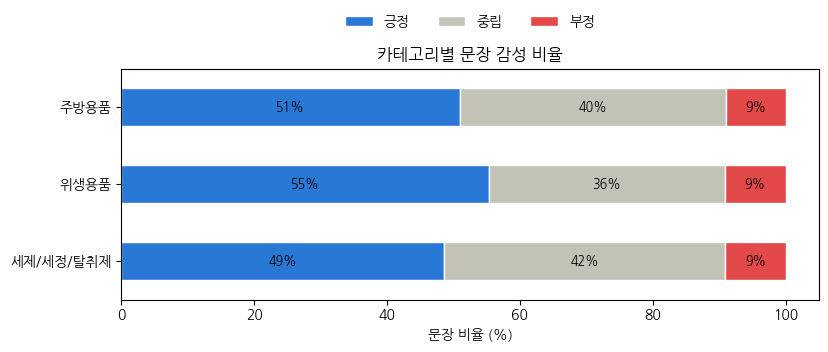

In [13]:
# 카테고리 × 감성 비율 표 (%)
# pd.crosstab(행, 열, normalize="index"): 카테고리마다 감성별 문장 비율(행 합계 = 1)을 표로 만듦
# [ORDER]: 열 순서를 긍정, 중립, 부정으로 맞춤, * 100: 백분율로 변환
ratio = pd.crosstab(sent["카테고리"], sent["감성"], normalize="index")[ORDER] * 100

# 비율 표를 소수 첫째 자리로 출력
print(ratio.round(1))

# 가로 누적 막대 (막대 사이 흰 테두리, 칸 안에 % 표시)
# .plot.barh(stacked=True): 카테고리마다 감성 비율을 옆으로 이어 붙인 가로 막대
# color: 감성 순서대로 색 지정, edgecolor="white": 칸 테두리를 흰색으로, figsize: 그림 크기(가로, 세로)
ax = ratio.plot.barh(stacked=True, color=[COLORS[k] for k in ORDER], edgecolor="white", figsize=(9, 3))

# ax.containers: 감성별 막대 묶음, 각 칸 가운데에 비율을 '49%' 형식으로 표시
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f%%", label_type="center", fontsize=9)

# x축 이름, y축 이름(비움), 그래프 제목
ax.set_xlabel("문장 비율 (%)")
ax.set_ylabel("")
ax.set_title("카테고리별 문장 감성 비율")

# 범례: 3칸 가로로, 그래프 위쪽 가운데에, 테두리 없이
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.12), frameon=False)

# 그래프 화면에 표시
plt.show()

✅ **결과 확인:** 어느 카테고리의 부정 문장 비율이 가장 높나요?

### 4-2. 문장 점수 분포

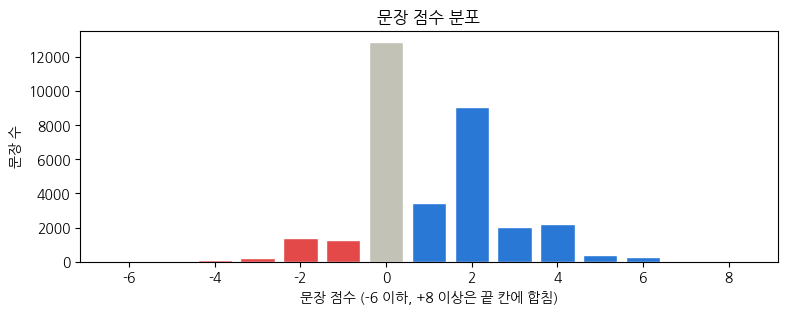

In [14]:
# 점수 -6 ~ +8 범위의 문장 수 (막대 하나 = 점수 1칸)
# .clip(-6, 8): -6보다 작은 점수는 -6으로, 8보다 큰 점수는 8로 바꿈
# .value_counts().sort_index(): 점수별 문장 수를 점수 순서로 정렬
counts = sent["점수"].clip(-6, 8).value_counts().sort_index()

# 0보다 크면 파랑, 0이면 회색, 0보다 작으면 빨강
# 점수마다 label로 감성을 구해 그 감성의 색을 목록으로 만듦
colors = [COLORS[label(s)] for s in counts.index]

# 새 그림 만들기 (가로 9, 세로 3)
plt.figure(figsize=(9, 3))

# 세로 막대: x = 점수, 높이 = 문장 수, 막대마다 색 지정
plt.bar(counts.index, counts.values, color=colors, edgecolor="white")

# x축 이름, y축 이름, 제목을 붙이고 화면에 표시
plt.xlabel("문장 점수 (-6 이하, +8 이상은 끝 칸에 합침)")
plt.ylabel("문장 수")
plt.title("문장 점수 분포")
plt.show()

✅ **결과 확인:** 0점(중립) 문장이 많은 이유는? → 감정 표현이 없는 설명 문장이거나, **사전에 없는 표현**("마음에 들어요", "빨리 왔어요")이기 때문입니다.

### 4-3. 워드클라우드: 긍정 문장 vs 부정 문장
글자가 클수록 많이 나온 명사입니다.

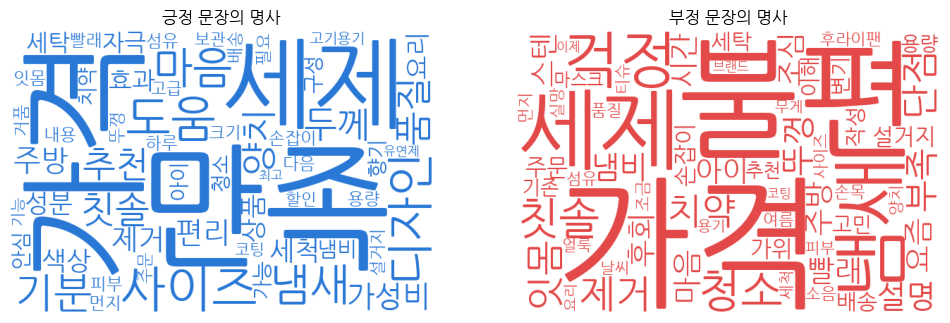

In [15]:
# os        : 파일 경로를 다루는 파이썬 기본 도구
# WordCloud : 워드클라우드를 만드는 클래스
import os
from wordcloud import WordCloud

# koreanize_matplotlib에 들어 있는 나눔고딕 글꼴 파일 경로
# koreanize_matplotlib.__file__ 이 있는 폴더 안의 fonts/NanumGothic.ttf 경로를 만듦
FONT = os.path.join(os.path.dirname(koreanize_matplotlib.__file__), "fonts", "NanumGothic.ttf")

# ===== ✏️ [입력] 그래프에서 뺄 흔한 명사 =====
STOP = {"제품", "사용", "구매", "구입", "생각", "정도", "부분", "후기", "느낌", "처음", "이번", "가격대", "지금"}
# ==========================================

# 감성별 명사 세기
# df_part의 모든 문장에서 명사를 하나씩 꺼내, STOP에 없는 명사만 개수를 셈
def count_nouns(df_part):
    return Counter(n for nouns in df_part["명사"] for n in nouns if n not in STOP)

# 긍정·부정 워드클라우드를 나란히 그리기
# plt.subplots(1, 2): 그림 하나에 가로로 그래프 칸 2개(axes[0], axes[1])를 만듦
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 왼쪽 칸에는 "긍정", 오른쪽 칸에는 "부정"을 차례로 그림
for ax, k in zip(axes, ["긍정", "부정"]):
    # 워드클라우드 설정: 한글 글꼴, 흰 배경, 600×400 크기, 단어 최대 60개,
    # color_func: 모든 단어를 그 감성의 색 하나로 칠함 (c=COLORS[k]로 현재 색을 고정)
    wc = WordCloud(font_path=FONT, background_color="white", width=600, height=400,
                   max_words=60, color_func=lambda *a, c=COLORS[k], **kw: c)
    # 그 감성 문장들의 명사 개수로 워드클라우드 만들기 (많이 나온 명사일수록 크게)
    wc.generate_from_frequencies(count_nouns(sent[sent["감성"] == k]))
    # 만든 워드클라우드를 칸에 그림으로 표시, 제목 붙이기, 축 숨기기
    ax.imshow(wc)
    ax.set_title(f"{k} 문장의 명사")
    ax.axis("off")

# 그래프 화면에 표시
plt.show()

✅ **결과 확인:** 부정 쪽에도 `가격`, `불편`처럼 진짜 단점과, `잇몸`, `빨래`처럼 **사용 상황**을 말하는 단어가 섞여 있습니다.

### 4-4. 카테고리별 아쉬운 점 단어

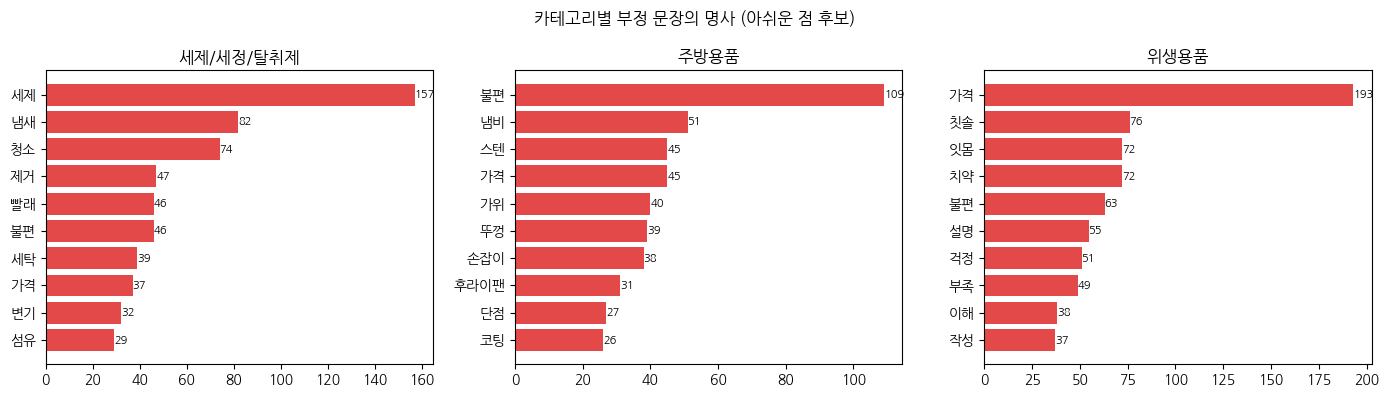

In [16]:
# 카테고리마다 부정 문장에 많이 나온 명사 10개
# .unique(): 카테고리 이름을 중복 없이 모음
cats = sent["카테고리"].unique()

# 카테고리 수만큼 가로로 그래프 칸 만들기
fig, axes = plt.subplots(1, len(cats), figsize=(14, 4))

# 칸 하나에 카테고리 하나씩 그림
for ax, cat in zip(axes, cats):
    # 이 카테고리의 부정 문장만 골라 명사를 세고, 많이 나온 10개를 (명사, 횟수)로 꺼냄
    top = count_nouns(sent[(sent["카테고리"] == cat) & (sent["감성"] == "부정")]).most_common(10)
    words, nums = zip(*top[::-1])                 # 많은 단어가 위로 오도록 뒤집기
    # 가로 막대: 명사별 횟수를 빨간색으로
    ax.barh(words, nums, color=COLORS["부정"])
    # 막대 끝에 횟수 숫자 표시, 칸 제목은 카테고리 이름
    ax.bar_label(ax.containers[0], fontsize=8)
    ax.set_title(cat)

# 그림 전체 제목, 칸끼리 겹치지 않게 간격 조정, 화면에 표시
fig.suptitle("카테고리별 부정 문장의 명사 (아쉬운 점 후보)")
plt.tight_layout()
plt.show()

✅ **결과 확인:** `세제`, `칫솔`, `냄비`처럼 **제품 이름 자체**가 위에 오기도 합니다. ✏️ 4-3 셀의 `STOP`에 넣고 다시 실행해 보세요.

### 4-5. 카테고리별 대표 불만 문장
점수가 가장 낮은(가장 부정적인) 20~80자 문장 3개씩입니다. **그래프의 단어가 실제로 어떤 문장에서 나왔는지** 확인하세요.

In [17]:
# 20~80자 부정 문장 중 점수가 낮은 순으로 카테고리마다 3개
# 감성이 "부정"이고 글자 수가 20 이상 80 이하인 문장만 고름
neg = sent[(sent["감성"] == "부정") & sent["문장"].str.len().between(20, 80)]

# 점수 오름차순(가장 부정적인 문장 먼저)으로 정렬 → 카테고리마다 앞 3개 → 카테고리 이름 순으로 정렬
worst = neg.sort_values("점수").groupby("카테고리").head(3).sort_values("카테고리")

# 표에서 한 칸에 보여 줄 최대 글자 수를 100으로 설정
pd.set_option("display.max_colwidth", 100)

# 카테고리, 점수, 문장 열만 표로 보기
worst[["카테고리", "점수", "문장"]]

,카테고리,점수,문장
4250,세제/세정/탈취제,-6,항상 사용할때마다 독한 냄새로 인해 힘들게 하곤 했는데 그 힘듦을 조금이나마 잊을 수 있는 제품이 있어서 저도 이번에 사용해봤습니다. ^^
3467,세제/세정/탈취제,-5,"매번 청소해야지 하면서도 냄새 맡기도 싫고, 솔로 빡빡 미는것도 너무 힘들어서 자꾸 미루게만 되는 욕실청소.."
6720,세제/세정/탈취제,-5,더러워지고 닦아도 깨끗해지지 않는 인덕션을 보면 한숨이 절로 나온다는 분은 얼릉 구매하 세요
19655,위생용품,-6,남편이 떨어지면 투덜대서 유난을 떤다고 생각했었는데 막상 사용해보니 없으면 불편하고 뭔가 찜찜한 부분이 많네요
31644,위생용품,-6,다만 가격이 일반 비누에 비해 조금 비싼편이고 향이 아이들이 맡기엔 거부감을 느껴서 싫다고 하네요.
23598,위생용품,-5,단점이라면 가격이 조금 비싸다는 점과 뚜껑이 열고 닫을 때 사용하기 불편합니다.
17858,주방용품,-6,비싸기만 하고 무겁고 짜증나서 돈이 아깝다는 생각이 들어 버리지도 못하고 ....
8918,주방용품,-6,연마제 없애는거 처음 해 봤는데 재미도 없고 힘든 작업이더라구요.ㅠㅠ
9780,주방용품,-5,더운여름 불앞에서 요리하는게 힘들었는데 구입해서 사용해보니 진작 사지 않은 것이 후회스러워요.


✅ **결과 확인:** 진짜 불만("가격이 비싸고 뚜껑이 불편합니다")도 있지만, **예전 제품이나 청소의 어려움을 설명하는 문장**("독한 냄새로 힘들었는데 …")도 섞여 있습니다. 감성사전 방식의 한계입니다.

### 4-6. 정답 세트로 정확도 확인
지금까지는 결과를 눈으로만 봤습니다. **사람이 미리 정답을 단 40문장**과 비교해 정확도를 계산합니다.

**정답 기준:** 이 문장이 **제품에 대해** 좋게(긍정) / 나쁘게(부정) 말하는가? 둘 다 아니면 중립.
- 예전 제품의 문제나 사용 상황을 설명하는 문장("잇몸이 안 좋아서 칫솔 쓰기가 힘들었어요")은 **중립**
- 데이터에서 긍정 14, 부정 13, 중립 13문장을 골라 정답을 달았습니다. **틀리기 쉬운 문장을 일부러 넣었으므로** 전체 데이터의 정확도와는 다릅니다.

In [18]:
# 정답 세트: (문장, 정답)
# 사람이 미리 정답(긍정/중립/부정)을 단 40문장을 (문장, 정답) 튜플의 리스트로 저장
GOLD = [
    ("제품이 질도 참 좋습니다.", "긍정"),
    ("맛도 그리 맵지도 않아서 좋습니다", "긍정"),
    ("품질도 정말 좋은 것 같습니다.", "긍정"),
    ("귀끈이 또 두꺼워서 착용했을 때 엄청 편합니다.", "긍정"),
    ("칫솔모가 굉장히 부드러워서 좋은 것 같네요.", "긍정"),
    ("디자인도 무척 좋습니다.", "긍정"),
    ("재질이 좋은지 칼집 흠이 잘 안나네요.", "긍정"),
    ("향도 은은하게 나서 저는 마음에 드네요", "긍정"),
    ("배송도 엄청 빨리 왔어요", "긍정"),
    ("일단 기능과 디자인이 너무 마음에 듭니다", "긍정"),
    ("거품도 풍성한 편입니다.", "긍정"),
    ("잇몸이 안 좋아서 이것 저것 치약을 많이 써봤는데 치약을 만나고 부터는 다른 거는 안씁니다", "긍정"),
    ("집에서나 차안에서 놔두고 부담없이 쓸 수 있는 물티슈네요", "긍정"),
    ("버블워시로 강력한 세척으로 섬유오염제거는 물론 옷얼룩제거, 옷 미세먼지 세탁까지 한번에 해결이 되더라구요.", "긍정"),
    ("마감이 좀 거친부분이 있어서 흠이네요ㅠㅠ", "부정"),
    ("세정력도 떨어지고 가득 채우면 서너장은 넣어야 하고 거품도 안 나고 정말 안 좋더라고요.", "부정"),
    ("다른 냄비에 비해 물 끓는 시간이 배로 걸렸어요.", "부정"),
    ("쌀 씻을 때에는 구멍이 좀 작아서 끼어서 불편해요.", "부정"),
    ("한가지 아쉬운 점은 소리가 크고 너무 진동이 심해서 이빨 닦을때 덜덜덜 떨린다는 겁니다", "부정"),
    ("한가지 조금 아쉬운건 수량은 많아서 좋은데 맛을 한가지만 선택할수 있는데 좀 그래요", "부정"),
    ("다만 절취선이 없어서 뜯을 때 잘 뜯기지가 않아서 불편해요.", "부정"),
    ("다만 가격이 비싼점은 있고요.", "부정"),
    ("살균효과는 있는 듯하지만 지속력이 너무 짧아서 아쉽습니다..ㅠㅠ", "부정"),
    ("단점이라고 하면 물빠짐 판 마감이 약간 날카로워요.", "부정"),
    ("제품 아이디어는 너무 좋은데 품질이 조금 아쉽네요^^", "부정"),
    ("근데 생각보다 찬물에 잘 안 녹는 것 같고 거품도 많이 안나 서 놀랐어요", "부정"),
    ("다만 다른 미용 티슈처럼 부드럽지 않습니다", "부정"),
    ("구매하고 싶은 분들이 계시다면 저처럼 후기를 참고하시기 바랍니다", "중립"),
    ("전에 쓰던 제품을 다 사용해서 새롭게 구매를 했는데요.", "중립"),
    ("오늘 리뷰하기 위해 들고 온 제품은 베이킹소다를 담은 주방세제입니다~", "중립"),
    ("만만한 반찬들 중 하나가 계란이잖아요~", "중립"),
    ("사용해 본 후기입니다", "중립"),
    ("읽어주셔서 감사합니다.", "중립"),
    ("건강한 하루 보내시길 바랍니다.", "중립"),
    ("요즘 장마라 빨래도 뭐든 잘 마르지 않고 축축해져 곰팡이냄새, 걸래냄새, 고양이 화장실 암모니아 냄새(고양이 화장실이 두부모래)가 금방 나서 급히 구매했어요.", "중립"),
    ("잇몸이 안좋아서 어떤 칫솔을 써도 힘들었거든요", "중립"),
    ("귀차니즘으로 인해 3주간 미뤄뒀던 후기를 지금부터 작성하려고 합니다.", "중립"),
    ("아쉬운 점이 있으면 말해주실래요?", "중립"),
    ("제가 귀 귀울여 잘 듣겠습니다.", "중립"),
    ("생각보다 크기도 큽니다.", "중립"),
]

# 정답 세트를 표로 만들고 단어 나누기
# GOLD를 '문장', '정답' 두 열짜리 표로 변환
gold = pd.DataFrame(GOLD, columns=["문장", "정답"])
# 정답 세트 문장을 형태소 분석해 문장마다 감성사전 모양의 단어 목록으로 바꿈
gold_words = [to_words(t) for t in kiwi.tokenize(gold["문장"].tolist())]

# 고치기 전·후 사전으로 각각 예측
# 문장마다 원본 사전(knu_raw)과 고친 사전(knu)으로 점수를 매겨 긍정/중립/부정으로 바꿈
gold["예측_전"] = [label(score(w, knu_raw)) for w in gold_words]
gold["예측_후"] = [label(score(w, knu)) for w in gold_words]

# 정확도 = 예측이 정답과 같은 비율
# (예측 == 정답)은 True/False, 평균을 내면 True(맞힘)의 비율
acc_before = (gold["예측_전"] == gold["정답"]).mean()
acc_after = (gold["예측_후"] == gold["정답"]).mean()
# 고치기 전·후 정확도를 백분율로 출력
print(f"정확도  고치기 전: {acc_before:.0%}  →  고친 후: {acc_after:.0%}")

# 결과 저장
# 정답 세트 표(문장, 정답, 예측_전, 예측_후)를 CSV로 저장 (utf-8-sig: 엑셀 한글 깨짐 방지)
gold.to_csv("evaluation.csv", index=False, encoding="utf-8-sig")

정확도  고치기 전: 55%  →  고친 후: 70%


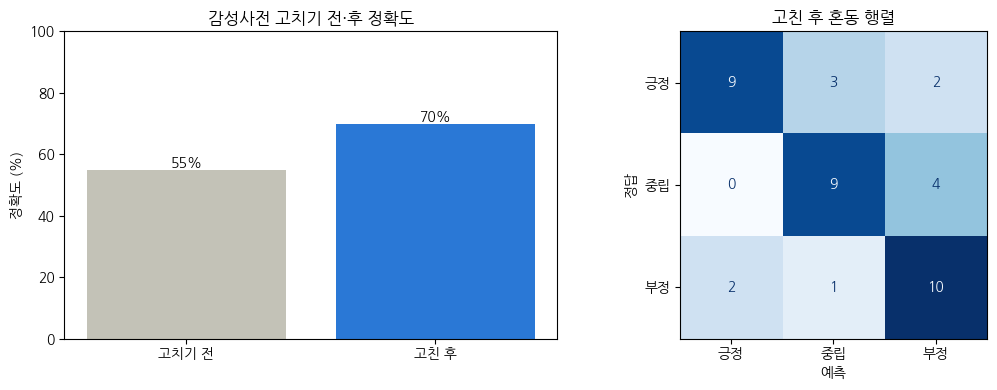

In [19]:
# ConfusionMatrixDisplay: 혼동 행렬(정답과 예측을 비교한 표)을 그리는 도구
from sklearn.metrics import ConfusionMatrixDisplay

# 그림 하나에 가로로 그래프 칸 2개 만들기
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# 왼쪽: 고치기 전·후 정확도 막대
# 막대 2개: 고치기 전(회색), 고친 후(파랑), 높이는 정확도(%)
axes[0].bar(["고치기 전", "고친 후"], [acc_before * 100, acc_after * 100], color=["#c3c2b7", "#2a78d6"])
# 막대 위에 '70%' 형식으로 값 표시
axes[0].bar_label(axes[0].containers[0], fmt="%.0f%%")
# y축 범위 0~100, y축 이름, 제목
axes[0].set_ylim(0, 100)
axes[0].set_ylabel("정확도 (%)")
axes[0].set_title("감성사전 고치기 전·후 정확도")

# 오른쪽: 혼동 행렬 (가로 = 예측, 세로 = 정답, 대각선 = 맞힌 문장 수)
# from_predictions(정답, 예측): 두 목록을 비교해 칸마다 문장 수를 세고 파란색 농도로 그림
#   labels=ORDER: 긍정·중립·부정 순서, colorbar=False: 색 막대 숨김, ax: 그릴 칸
ConfusionMatrixDisplay.from_predictions(gold["정답"], gold["예측_후"], labels=ORDER,
                                        cmap="Blues", colorbar=False, ax=axes[1])
# 제목, x축 이름, y축 이름
axes[1].set_title("고친 후 혼동 행렬")
axes[1].set_xlabel("예측")
axes[1].set_ylabel("정답")

# 칸끼리 겹치지 않게 간격 조정, 화면에 표시
plt.tight_layout()
plt.show()

✅ **결과 확인:** 틀린 문장을 직접 읽어 보세요. 왜 틀렸을까요?

In [20]:
# 고친 후에도 틀린 문장
# 예측_후가 정답과 다른 행만 골라 문장, 정답, 예측_후 열을 표로 보기
gold[gold["예측_후"] != gold["정답"]][["문장", "정답", "예측_후"]]

,문장,정답,예측_후
8,배송도 엄청 빨리 왔어요,긍정,중립
9,일단 기능과 디자인이 너무 마음에 듭니다,긍정,중립
11,잇몸이 안 좋아서 이것 저것 치약을 많이 써봤는데 치약을 만나고 부터는 다른 거는 안씁니다,긍정,부정
12,집에서나 차안에서 놔두고 부담없이 쓸 수 있는 물티슈네요,긍정,중립
13,"버블워시로 강력한 세척으로 섬유오염제거는 물론 옷얼룩제거, 옷 미세먼지 세탁까지 한번에 해결이 되더라구요.",긍정,부정
19,한가지 조금 아쉬운건 수량은 많아서 좋은데 맛을 한가지만 선택할수 있는데 좀 그래요,부정,긍정
24,제품 아이디어는 너무 좋은데 품질이 조금 아쉽네요^^,부정,긍정
25,근데 생각보다 찬물에 잘 안 녹는 것 같고 거품도 많이 안나 서 놀랐어요,부정,중립
35,잇몸이 안좋아서 어떤 칫솔을 써도 힘들었거든요,중립,부정
36,귀차니즘으로 인해 3주간 미뤄뒀던 후기를 지금부터 작성하려고 합니다.,중립,부정


### 결과 저장

In [21]:
# 카테고리별 감성 비율 저장
# 비율 표를 소수 첫째 자리로 반올림해 CSV로 저장 (utf-8-sig: 엑셀 한글 깨짐 방지)
ratio.round(1).to_csv("sentiment_by_category.csv", encoding="utf-8-sig")

# 저장한 파일 이름 출력
print("저장 완료: review_sentences.csv, sentiment_by_category.csv, evaluation.csv")

저장 완료: review_sentences.csv, sentiment_by_category.csv, evaluation.csv


---
## 정리

### ✅ 한 줄 정리
**리뷰를 문장으로 나누고, 생활용품에 맞게 고친 감성사전으로 문장마다 감성을 매겨, 카테고리별 아쉬운 점을 찾았다.**

### 🗂️ 만든 파일
| 파일 | 내용 |
|---|---|
| `review_sentences.csv` | 정제 데이터셋 (문장ID, 리뷰ID, 카테고리, 상품명, 문장, 단어, 명사) |
| `sentiment_by_category.csv` | 카테고리별 긍정·중립·부정 문장 비율 |
| `evaluation.csv` | 정답 세트와 고치기 전·후 예측 |

### 🤔 생각해 볼 점 (한계)
| 한계 | 예 | 더 나은 방법 |
|---|---|---|
| **사전에 없는 표현** | "마음에 들어요", "빨리 왔어요" → 0점 | 두 단어 표현 추가, 학습된 감성 모델 |
| **사용 상황 설명도 부정으로** | "잇몸이 안 좋아서 칫솔 쓰기가 힘들었어요" | 과거 표현(`예전`, `전에는`) 처리 |
| **'하지만' 뒤가 진짜 의견** | "아이디어는 좋은데 품질이 아쉽네요" | 접속 표현 뒤 문장에 가중치 |
| **인사 문장 빼기 규칙** | `오늘은`이 들어간 평가 문장도 빠짐 | 규칙을 더 좁게 조정 |
| **정답 세트가 작고 주관적** | 40문장, 한 사람이 정답을 정함 | 여러 사람이 정답 달고 일치도 확인 |
| **SNS 리뷰의 치우침** | 대부분 칭찬 | 쇼핑몰 리뷰와 비교 |

.

**참고:** [Kiwi (kiwipiepy)](https://github.com/bab2min/kiwipiepy) · [KNU 한국어 감성사전](https://github.com/park1200656/KnuSentiLex) · [wordcloud](https://github.com/amueller/word_cloud) · [koreanize-matplotlib](https://github.com/ychoi-kr/koreanize-matplotlib)